<a href="https://colab.research.google.com/github/Shekinah-Ineza/formative3-group19/blob/main/Formative3_Part4_GradientDescent_Team19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np

X = np.array([[1, 3],
              [4, 10]])        # 2 data points, 2 features
y = np.array([5, 6])           # targets
m = np.array([-1.0, 2.0])      # initial slopes
b = np.array([1.0, 1.0])       # initial intercept
alpha = 0.01                   # learning rate (confirm with team)
n_updates = 3                  # one per group member

In [3]:
def predict(X, m, b):
    """y_hat = X m + b (matrix multiplication)."""
    return X @ m + b

def compute_mse(y_hat, y):
    """J = (1/n) * sum((y_hat - y)^2)"""
    return np.mean((y_hat - y) ** 2)

def compute_gradients(X, y_hat, y):
    """dJ/dm = (2/n) X^T (y_hat - y),  dJ/db = (2/n) (y_hat - y)"""
    n = len(y)
    error = y_hat - y
    grad_m = (2 / n) * (X.T @ error)
    grad_b = (2 / n) * error
    return grad_m, grad_b

def update_parameters(m, b, grad_m, grad_b, alpha):
    """Move each parameter against its gradient."""
    return m - alpha * grad_m, b - alpha * grad_b

In [4]:
history = {"m": [m.copy()], "b": [b.copy()], "mse": []}
iteration_rows = []

for i in range(1, n_updates + 1):
    y_hat = predict(X, m, b)
    error = y_hat - y
    mse = compute_mse(y_hat, y)
    grad_m, grad_b = compute_gradients(X, y_hat, y)

    m, b = update_parameters(m, b, grad_m, grad_b, alpha)

    updated_y_hat = predict(X, m, b)
    updated_mse = compute_mse(updated_y_hat, y)

    iteration_rows.append({
        "Update": i,
        "Predictions before": y_hat.copy(),
        "Errors before": error.copy(),
        "Gradient m": grad_m.copy(),
        "Gradient b": grad_b.copy(),
        "Updated m": m.copy(),
        "Updated b": b.copy(),
        "MSE before": mse,
        "MSE after": updated_mse,
    })

    history["m"].append(m.copy())
    history["b"].append(b.copy())
    history["mse"].append(mse)

final_y_hat = predict(X, m, b)
print("Final predictions:", final_y_hat)
print("Final MSE:", round(compute_mse(final_y_hat, y), 6))

Final predictions: [2.954063 6.378335]
Final MSE: 2.164498


In [5]:
from IPython.display import Markdown, display


def show_iteration_table(rows):
    """Display the recorded gradient descent calculations."""
    def format_value(value):
        if isinstance(value, np.ndarray):
            return np.array2string(value, precision=6)
        if isinstance(value, (float, np.floating)):
            return f"{value:.6f}"
        return str(value)

    columns = list(rows[0])
    lines = [
        "| " + " | ".join(columns) + " |",
        "| " + " | ".join(["---"] * len(columns)) + " |",
    ]

    for row in rows:
        values = [format_value(row[column]) for column in columns]
        lines.append("| " + " | ".join(values) + " |")

    display(Markdown("\n".join(lines)))


show_iteration_table(iteration_rows)

| Update | Predictions before | Errors before | Gradient m | Gradient b | Updated m | Updated b | MSE before | MSE after |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | [ 6. 17.] | [ 1. 11.] | [ 45. 113.] | [ 1. 11.] | [-1.45  0.87] | [0.99 0.89] | 61.000000 | 6.503300 |
| 2 | [2.15 3.79] | [-2.85 -2.21] | [-11.69 -30.65] | [-2.85 -2.21] | [-1.3331  1.1765] | [1.0185 0.9121] | 6.503300 | 2.497400 |
| 3 | [3.2149 7.3447] | [-1.7851  1.3447] | [3.5937 8.0917] | [-1.7851  1.3447] | [-1.369037  1.095583] | [1.036351 0.898653] | 2.497400 | 2.164498 |

## Comparison with our manual calculations

Each row shows predictions, errors and gradients before an update,
followed by the updated parameters and the resulting MSE.

For a learning rate of 0.01, the MSE decreases from 61 initially
to approximately 6.503300, 2.497400 and 2.164498 after three updates.

Compare each row with the corresponding member's manual calculation.
The parameter values can change direction while the error decreases.

In [6]:
from scipy.differentiate import derivative

def compute_derivative(equation, x_value):
    """Numerical derivative of a one-variable equation at x_value (SciPy)."""
    return float(derivative(equation, x_value).df)

# Test: the derivative of x^2 at x = 3 should be 6
print(compute_derivative(lambda x: x ** 2, 3))

5.999999999999972


In [7]:
def partial_derivative(cost_fn, params, index):
    """dJ/d(params[index]) numerically, holding the other parameters fixed."""
    def f(value):
        p = params.copy()
        p[index] = value
        return cost_fn(p)
    return compute_derivative(np.vectorize(f), params[index])

# Use the ORIGINAL starting values (m and b were changed by the loop)
m0 = np.array([-1.0, 2.0])
b0 = np.array([1.0, 1.0])
cost = lambda p: compute_mse(predict(X, p, b0), y)

print("SciPy dJ/dm1 =", round(partial_derivative(cost, m0, 0), 4))
print("SciPy dJ/dm2 =", round(partial_derivative(cost, m0, 1), 4))
print("Our formula   =", compute_gradients(X, predict(X, m0, b0), y)[0])

SciPy dJ/dm1 = 45.0
SciPy dJ/dm2 = 113.0
Our formula   = [ 45. 113.]


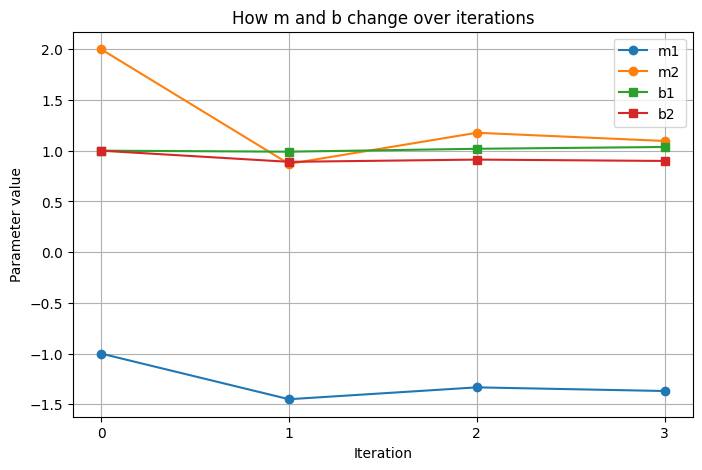

In [8]:
import matplotlib.pyplot as plt

m_history = np.array(history["m"])   # shape (4, 2): iterations 0 to 3
b_history = np.array(history["b"])
iterations = list(range(len(m_history)))

def plot_parameters(iterations, m_history, b_history):
    """Line plot of m1, m2, b1, b2 across iterations."""
    plt.figure(figsize=(8, 5))
    plt.plot(iterations, m_history[:, 0], marker="o", label="m1")
    plt.plot(iterations, m_history[:, 1], marker="o", label="m2")
    plt.plot(iterations, b_history[:, 0], marker="s", label="b1")
    plt.plot(iterations, b_history[:, 1], marker="s", label="b2")
    plt.xlabel("Iteration")
    plt.ylabel("Parameter value")
    plt.title("How m and b change over iterations")
    plt.xticks(iterations)
    plt.legend()
    plt.grid(True)
    plt.show()

plot_parameters(iterations, m_history, b_history)

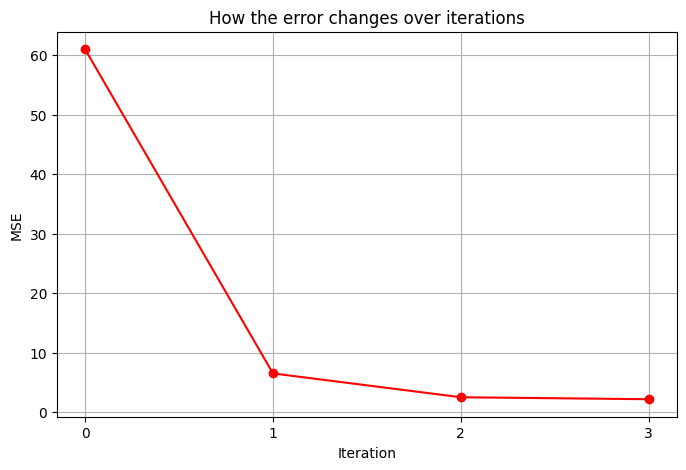

In [9]:
# history["mse"] holds the error BEFORE each update, so add the error after the last update
mse_values = history["mse"] + [compute_mse(predict(X, m, b), y)]

def plot_error(iterations, mse_values):
    """Line plot of the MSE across iterations."""
    plt.figure(figsize=(8, 5))
    plt.plot(iterations, mse_values, marker="o", color="red")
    plt.xlabel("Iteration")
    plt.ylabel("MSE")
    plt.title("How the error changes over iterations")
    plt.xticks(iterations)
    plt.grid(True)
    plt.show()

plot_error(iterations, mse_values)